# ORI 2026 — EKSPERIMENT 2: PREDVIĐANJE PRINOSA (Regresija)
## 2-1, 2-2, 2-3 (a/b/c podslučajevi) — sve regresija

Ovaj notebook:
- ✅ Učitava CSV fajlove (Date, Price, Open, High, Low, Vol.)
- ✅ Izveštaj o nedostajućim vrednostima po paru
- ✅ Indikatori pomoću `ta` paketa (SMA, EMA, ROC, RSI, MACD, STD, ATR, KAMA, SAR, CCI, CMO)
- ✅ **Target = buduće stope prinosa ROC(1), ROC(3), ROC(5), ROC(10)** — problem regresije
- ✅ Eksperiment 2-1: cene / indikatori / cene+indikatori → ROC(1,3,5,10)
- ✅ Eksperiment 2-2: + ROC od ulaznih varijabli → ROC(1,3,5,10)
- ✅ Eksperiment 2-3: + ROC i SMA od ulaznih varijabli → ROC(1,3,5,10)
- ✅ MLP regresor (64,32,16) za svaku kombinaciju (par × podslučaj × horizont)
- ✅ Metrike: MAE, RMSE, R², MAPE, Direction Accuracy
- ✅ Confusion Matrix smera kretanja prinosa (UP/DOWN)
- ✅ Sve vizualizacije i Excel export

### Razlika u odnosu na Eksperiment 1:
- **Eksperiment 1** → predviđali smo **buduće CENE** (Price t+h)
- **Eksperiment 2** → predviđamo **buduće PRINOSE** (ROC t+h = stopa promene cene)
  - ROC(h) = (Price[t+h] - Price[t]) / Price[t] × 100


In [1]:
import pandas as pd
import numpy as np
import os
import glob
import warnings
import itertools
from math import sqrt
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings('ignore')

possible_dirs = [".", "data", "./data", "../data"]
INPUT_DIR = ".."

for dir_path in possible_dirs:
    if os.path.exists(dir_path):
        csv_files = glob.glob(os.path.join(dir_path, "*_Data.csv"))
        if csv_files and len(csv_files) >= 5:
            INPUT_DIR = dir_path
            break

print(f"✓ CSV fajlovi pronađeni u: {INPUT_DIR}")
print(f"✓ Sve biblioteke učitane!")

✓ CSV fajlovi pronađeni u: data
✓ Sve biblioteke učitane!


## 📋 FAZA 1: Priprema podataka

In [2]:
def load_csv(path):
    df = pd.read_csv(path, encoding="utf-8-sig")
    df.columns = [c.strip().strip('"') for c in df.columns]
    return df


def clean_numeric_column(series):
    """Konvertuje string kolonu (zarezi/procenti/K,M,B sufiksi) u numeričku."""
    s = series.astype(str).str.replace(",", "", regex=False)
    s = s.str.replace("%", "", regex=False)

    def parse_suffix(val):
        if not isinstance(val, str):
            return np.nan if pd.isna(val) else float(val)
        val = val.strip()
        if val in ("", "nan", "None", "-"):
            return np.nan
        multiplier = 1
        if val.endswith("K"):
            multiplier, val = 1_000, val[:-1]
        elif val.endswith("M"):
            multiplier, val = 1_000_000, val[:-1]
        elif val.endswith("B"):
            multiplier, val = 1_000_000_000, val[:-1]
        try:
            return float(val) * multiplier
        except ValueError:
            return np.nan

    return s.apply(parse_suffix)


csv_files = sorted(glob.glob(os.path.join(INPUT_DIR, "*_Data.csv")))
print(f"Pronađeno {len(csv_files)} CSV fajlova:\n")

all_data = []
missing_report = []

for path in csv_files:
    pair_name = os.path.basename(path).replace("_Data.csv", "")
    df_raw = load_csv(path)

    df_raw["Date"] = pd.to_datetime(df_raw["Date"], format="%m/%d/%Y", errors="coerce")

    numeric_cols = [c for c in ["Price", "Open", "High", "Low", "Change %"] if c in df_raw.columns]
    for col in numeric_cols:
        df_raw[col] = clean_numeric_column(df_raw[col])

    total_rows = len(df_raw)
    cols_to_check = ["Date"] + numeric_cols
    missing_counts = df_raw[cols_to_check].isna().sum()
    missing_pct = (missing_counts / total_rows * 100).round(2)

    report_row = {"Pair": pair_name, "Total_Rows": total_rows}
    for col in cols_to_check:
        report_row[f"{col}_missing_%"] = missing_pct[col]
    missing_report.append(report_row)

    keep_cols = ["Date"] + numeric_cols
    df = df_raw[keep_cols].dropna(subset=["Date", "Price"])
    df["Pair"] = pair_name

    all_data.append(df)
    print(f"  ✓ {pair_name:10s}: {len(df)} redova (od {total_rows} ukupno)")

# Ukloni redove iz USDCNY čiji datum se ne javlja kod nijednog drugog para
other_dates = set()
for df in all_data:
    if df["Pair"].iloc[0] != "USDCNY":
        other_dates.update(df["Date"])

for i, df in enumerate(all_data):
    if df["Pair"].iloc[0] == "USDCNY":
        before = len(df)
        all_data[i] = df[df["Date"].isin(other_dates)]
        removed = before - len(all_data[i])
        if removed > 0:
            print(f"\n  ⚠ USDCNY: uklonjeno {removed} redova sa datumima koji se ne javljaju kod ostalih parova "
                  f"({before} → {len(all_data[i])})")

currency_all = pd.concat(all_data, ignore_index=True)
currency_all = currency_all.sort_values(["Pair", "Date"]).reset_index(drop=True)

print(f"\n✓ Ukupno: {len(currency_all)} redova za {currency_all['Pair'].nunique()} parova")

Pronađeno 6 CSV fajlova:

  ✓ EURUSD    : 2610 redova (od 2610 ukupno)
  ✓ USDCAD    : 2610 redova (od 2610 ukupno)
  ✓ USDCHF    : 2610 redova (od 2610 ukupno)
  ✓ USDCNY    : 2611 redova (od 2611 ukupno)
  ✓ USDGBP    : 2610 redova (od 2610 ukupno)
  ✓ USDJPY    : 2610 redova (od 2610 ukupno)

  ⚠ USDCNY: uklonjeno 1 redova sa datumima koji se ne javljaju kod ostalih parova (2611 → 2610)

✓ Ukupno: 15660 redova za 6 parova


### 📊 Izveštaj o nedostajućim vrednostima po valutnom paru

In [3]:
missing_df = pd.DataFrame(missing_report)
print("="*80)
print("UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)")
print("="*80 + "\n")
print(missing_df.to_string(index=False))

UDEO NEDOSTAJUĆIH VREDNOSTI PO PARU (%)

  Pair  Total_Rows  Date_missing_%  Price_missing_%  Open_missing_%  High_missing_%  Low_missing_%  Change %_missing_%
EURUSD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCAD        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCHF        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDCNY        2611             0.0              0.0             0.0             0.0            0.0                 0.0
USDGBP        2610             0.0              0.0             0.0             0.0            0.0                 0.0
USDJPY        2610             0.0              0.0             0.0             0.0            0.0                 0.0


## 🔧 FAZA 2: Inženjering indikatora (paket `ta`)

In [4]:
from ta.trend import SMAIndicator, EMAIndicator, MACD, CCIIndicator, PSARIndicator
from ta.momentum import ROCIndicator, RSIIndicator
from ta.volatility import AverageTrueRange
from stockstats import StockDataFrame

INDICATOR_COLS = [
    "SMA_14", "EMA_14", "ROC_14", "RSI_14",
    "MACD", "MACD_Signal", "MACD_Hist",
    "STD_14", "ATR_14",
    "KAMA_14", "SAR", "CCI_14", "CMO_14"
]

def calculate_indicators(pair_df):
    close = pair_df["Price"]
    high  = pair_df["High"] if "High" in pair_df.columns else close
    low   = pair_df["Low"]  if "Low"  in pair_df.columns else close

    out = pd.DataFrame(index=pair_df.index)

    out["SMA_14"] = SMAIndicator(close=close, window=14).sma_indicator()
    out["EMA_14"] = EMAIndicator(close=close, window=14).ema_indicator()
    out["ROC_14"] = ROCIndicator(close=close, window=14).roc()
    out["RSI_14"] = RSIIndicator(close=close, window=14).rsi()

    macd = MACD(close=close, window_slow=26, window_fast=12, window_sign=9)
    out["MACD"]        = macd.macd()
    out["MACD_Signal"] = macd.macd_signal()
    out["MACD_Hist"]   = macd.macd_diff()

    out["STD_14"] = close.rolling(14).std()
    out["ATR_14"] = AverageTrueRange(high=high, low=low, close=close, window=14).average_true_range()
    out["CCI_14"] = CCIIndicator(high=high, low=low, close=close, window=14).cci()

    psar = PSARIndicator(high=high, low=low, close=close, step=0.025, max_step=0.25)
    out["SAR"] = psar.psar()

    stock = StockDataFrame.retype(pd.DataFrame({
        "close":  close.values,
        "high":   high.values,
        "low":    low.values,
        "open":   close.values,
        "volume": np.ones(len(close))
    }, index=pair_df.index))

    out["KAMA_14"] = stock["kama_14"]
    out["CMO_14"]  = stock["cmo_14"]

    return out


print("Računanje indikatora pomoću `ta` paketa...\n")

all_features = []
for pair_name in currency_all["Pair"].unique():
    pair_data  = currency_all[currency_all["Pair"] == pair_name].sort_values("Date").reset_index(drop=True)
    indicators = calculate_indicators(pair_data)
    indicators["Date"]  = pair_data["Date"].values
    indicators["Price"] = pair_data["Price"].values
    indicators["Pair"]  = pair_name
    all_features.append(indicators)
    print(f"  ✓ {pair_name}: {len(indicators)} redova")

features = pd.concat(all_features, ignore_index=True)
features  = features[["Pair", "Date", "Price"] + INDICATOR_COLS]
print(f"\n✓ Shape: {features.shape}")

  ✓ USDJPY: 2610 redova

✓ Shape: (15660, 16)


## 🧪 FAZA 3: Helper funkcije i TARGET generatori

### ⚠️ Ključna razlika od Eksperimenta 1:
**Target** sada nije buduća cena, već buduća stopa prinosa:

```
ROC_target(h) = (Price[t+h] - Price[t]) / Price[t] × 100
```

Ovo je tipičan **problem regresije prinosa** koji se koristi u finansijama.


In [5]:
def add_roc(df, cols, n):
    """ROC(n) za svaku kolonu u cols: (x[t] - x[t-n]) / x[t-n] * 100.
    Inf vrednosti sanitizovane u NaN."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        roc = df[c].pct_change(n) * 100
        roc = roc.replace([np.inf, -np.inf], np.nan)
        out[f"ROC{n}_{c}"] = roc
    return out

def add_sma(df, cols, n):
    """SMA(n) za svaku kolonu u cols."""
    out = pd.DataFrame(index=df.index)
    for c in cols:
        out[f"SMA{n}_{c}"] = df[c].rolling(n).mean()
    return out

def add_return_targets(df, horizons):
    """
    Dodaj kolone ROC_Target_h = buduća stopa prinosa za horizont h.

    ROC_Target(h) = (Price[t+h] - Price[t]) / Price[t] * 100

    Ovo je pravi prinos (Rate of Change) koji predviđamo u Eksperimentu 2.
    Razlika od Eksperimenta 1: tamo smo predviđali apsolutnu cenu Price[t+h],
    ovde predviđamo relativnu stopu promene u %.
    """
    out = pd.DataFrame(index=df.index)
    for h in horizons:
        future_price = df["Price"].shift(-h)
        roc = (future_price - df["Price"]) / df["Price"].abs().clip(lower=1e-9) * 100
        roc = roc.replace([np.inf, -np.inf], np.nan)
        out[f"ROC_Target_{h}"] = roc
    return out

print("✓ Helper funkcije definisane (ROC, SMA, ROC_Target generatori)")
print()
print("Primeri ROC targeta za EURUSD (prve 5 vrednosti - biće NaN na kraju):")
sample_pair = features[features['Pair'] == features['Pair'].unique()[0]].sort_values('Date').reset_index(drop=True)
sample_targets = add_return_targets(sample_pair, [1, 3, 5, 10])
print(sample_targets.tail(15).to_string())

✓ Helper funkcije definisane (ROC, SMA, ROC_Target generatori)

Primeri ROC targeta za EURUSD (prve 5 vrednosti - biće NaN na kraju):
      ROC_Target_1  ROC_Target_3  ROC_Target_5  ROC_Target_10
2595      0.110733      0.000000     -0.255537       0.272572
2596     -0.051051     -0.263762      0.068068       0.161661
2597     -0.059590     -0.314974      0.408615       0.008513
2598     -0.153322      0.178876      0.323680       0.051107
2599     -0.102372      0.622761      0.477734       0.204743
2600      0.435525      0.580700      0.529462            NaN
2601      0.289091      0.144546      0.093529            NaN
2602     -0.144129     -0.194998     -0.398474            NaN
2603      0.000000     -0.050942     -0.271693            NaN
2604     -0.050942     -0.254712     -0.271693            NaN
2605      0.000000     -0.220863           NaN            NaN
2606     -0.203874     -0.220863           NaN            NaN
2607     -0.017024           NaN           NaN            Na

## 🧠 FAZA 4: MLP Regresor — konfiguracija

In [6]:
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error

N_LAGS            = 5   # broj lagova za cene
N_LAGS_INDICATORS = 2   # broj lagova za indikatore (smoothed signali, manje lagova)
TEST_SIZE         = 0.2

# Iste MLP params kao u Eksperimentu 1 — konzistentnost radi poređenja
# (arhitektura piramidalnog tipa 64→32→16→1, identično duhu PyTorch/Keras
#  tutorijala: skriveni slojevi se sužavaju, izlazni sloj uvek 1 neuron sa
#  linearnom (identity) aktivacijom jer je u pitanju regresija — to MLPRegressor
#  radi automatski, pa 'activation' parametar ovde utiče samo na SKRIVENE slojeve)
MLP_PARAMS = {
    'hidden_layer_sizes': (64, 32, 16),
    'activation':         'relu',
    'solver':             'adam',
    'learning_rate_init': 0.001,
    'max_iter':           2000,
    'early_stopping':     True,
    'validation_fraction': 0.1,
    'n_iter_no_change':   25,
    'alpha':              0.001,
    'random_state':       42,
    'verbose':            0,
}

RETURN_HORIZONS = [1, 3, 5, 10]   # ROC(1), ROC(3), ROC(5), ROC(10)

def mape_safe(y_true, y_pred, eps=1e-9):
    """MAPE — siguran na nule u y_true."""
    mask = np.abs(y_true) > eps
    if mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def direction_accuracy(y_true, y_pred):
    """Procenat pravilno predviđenih znakova prinosa (pozitivan/negativan).
    Ovo je drugačije od Eksperimenta 1: tamo smo merili smer PROMENE cene,
    ovde merimo smer samog PRINOSA (da li je prinos pozitivan ili negativan).
    """
    if len(y_true) == 0:
        return np.nan
    correct = np.sign(y_true) == np.sign(y_pred)
    return correct.mean() * 100

def run_regression(X, y, test_size=TEST_SIZE, dates=None, scaler_type='standard'):
    """Treniraj MLP regresor, vrati metrike, predikcije i learning curve na test skupu.

    Best practice (scikit-learn docs + PyTorch/MLM tutorial): scaler se
    fit-uje SAMO na train skupu, a potom se ISTI scaler primenjuje i na
    train i na test — nikad se ne fit-uje na celom skupu (data leakage).
    """
    split_idx = int(len(X) * (1 - test_size))
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]

    if len(X_train) < 30 or len(X_test) < 10:
        return None

    Scaler = RobustScaler if scaler_type == 'robust' else StandardScaler
    scaler = Scaler()
    X_train_s = scaler.fit_transform(X_train)   # fit SAMO na train
    X_test_s  = scaler.transform(X_test)        # transform (ne fit!) na test

    model = MLPRegressor(**MLP_PARAMS)
    model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)

    mae     = mean_absolute_error(y_test, y_pred)
    rmse    = float(np.sqrt(mean_squared_error(y_test, y_pred)))
    r2      = r2_score(y_test, y_pred)
    mape    = mape_safe(y_test, y_pred)
    medae   = median_absolute_error(y_test, y_pred)   # robusna na outliere (TDS tutorial)
    dir_acc = direction_accuracy(y_test, y_pred)

    test_dates = dates[split_idx:] if dates is not None else None
    converged  = model.n_iter_ < MLP_PARAMS['max_iter']

    # Learning curve (gubitak po iteracijama) — analogno history listi iz
    # PyTorch tutoriala i Keras `loss`/`val_loss` krivama iz TDS tutoriala.
    loss_curve = list(getattr(model, 'loss_curve_', []))
    val_scores = list(getattr(model, 'validation_scores_', []))

    return {
        "MAE": mae, "RMSE": rmse, "R2": r2, "MAPE": mape, "MedAE": medae, "DirAcc": dir_acc,
        "Train_Size": len(X_train), "Test_Size": len(X_test),
        "y_test": y_test, "y_pred": y_pred, "test_dates": test_dates,
        "n_iter": model.n_iter_, "converged": converged, "n_features": X.shape[1],
        "loss_curve": loss_curve, "validation_scores": val_scores,
    }

print(f"✓ MLP Parametri: {MLP_PARAMS}")
print(f"✓ Horizonti prinosa: ROC{RETURN_HORIZONS}")
print("✓ Dodato: MedAE metrika + learning curve (loss_curve_, validation_scores_) po modelu")

✓ MLP Parametri: {'hidden_layer_sizes': (64, 32, 16), 'activation': 'relu', 'solver': 'adam', 'learning_rate_init': 0.001, 'max_iter': 2000, 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 25, 'alpha': 0.001, 'random_state': 42, 'verbose': 0}
✓ Horizonti prinosa: ROC[1, 3, 5, 10]
✓ Dodato: MedAE metrika + learning curve (loss_curve_, validation_scores_) po modelu


## 🧪 EKSPERIMENT 2-1: Predikcija prinosa — osnovni feature seti

### Feature seti:
- **a)** Lagovane CENE → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **b)** Lagovani INDIKATORI → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **c)** Lagovane CENE + lagovani INDIKATORI → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)


In [7]:
results_all = []       # Sakuplja rezultate svih eksperimenata
predictions_2_1 = {}   # {(pair, subcase, horizon): {dates, y_test, y_pred}}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # ── Feature blokovi ────────────────────────────────────────────────────
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)

    # ── Targetni prinosi ───────────────────────────────────────────────────
    targets = add_return_targets(pdf, RETURN_HORIZONS)

    feature_sets = {
        'a) cene':           (price_lags,                                                   'standard'),
        'b) indikatori':     (indicator_lags,                                               'robust'),
        'c) cene+indikatori':(pd.concat([price_lags, indicator_lags], axis=1),              'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in RETURN_HORIZONS:
            target_col = f'ROC_Target_{h}'
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X         = combo[X_df.columns].values
            y         = combo[target_col].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-1 {subcase} | {pair_name} | ROC({h})] "
                  f"MAE={metrics['MAE']:.4f} RMSE={metrics['RMSE']:.4f} "
                  f"R2={metrics['R2']:.4f} DirAcc={metrics['DirAcc']:.1f}% "
                  f"| feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '2-1', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'],   'MAPE': metrics['MAPE'], 'MedAE': metrics['MedAE'],
                'DirAcc': metrics['DirAcc'],
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_2_1[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
                'loss_curve': metrics['loss_curve'],
                'validation_scores': metrics['validation_scores'],
            }

print("\n✓ Eksperiment 2-1 završen.")

[2-1 c) cene+indikatori | USDJPY | ROC(10)] MAE=2.1296 RMSE=2.7609 R2=-1.1211 DirAcc=54.4% | feat=44 iter=426 ✓konv.

✓ Eksperiment 2-1 završen.


### 📈 Vizualizacija predikcija — Eksperiment 2-1

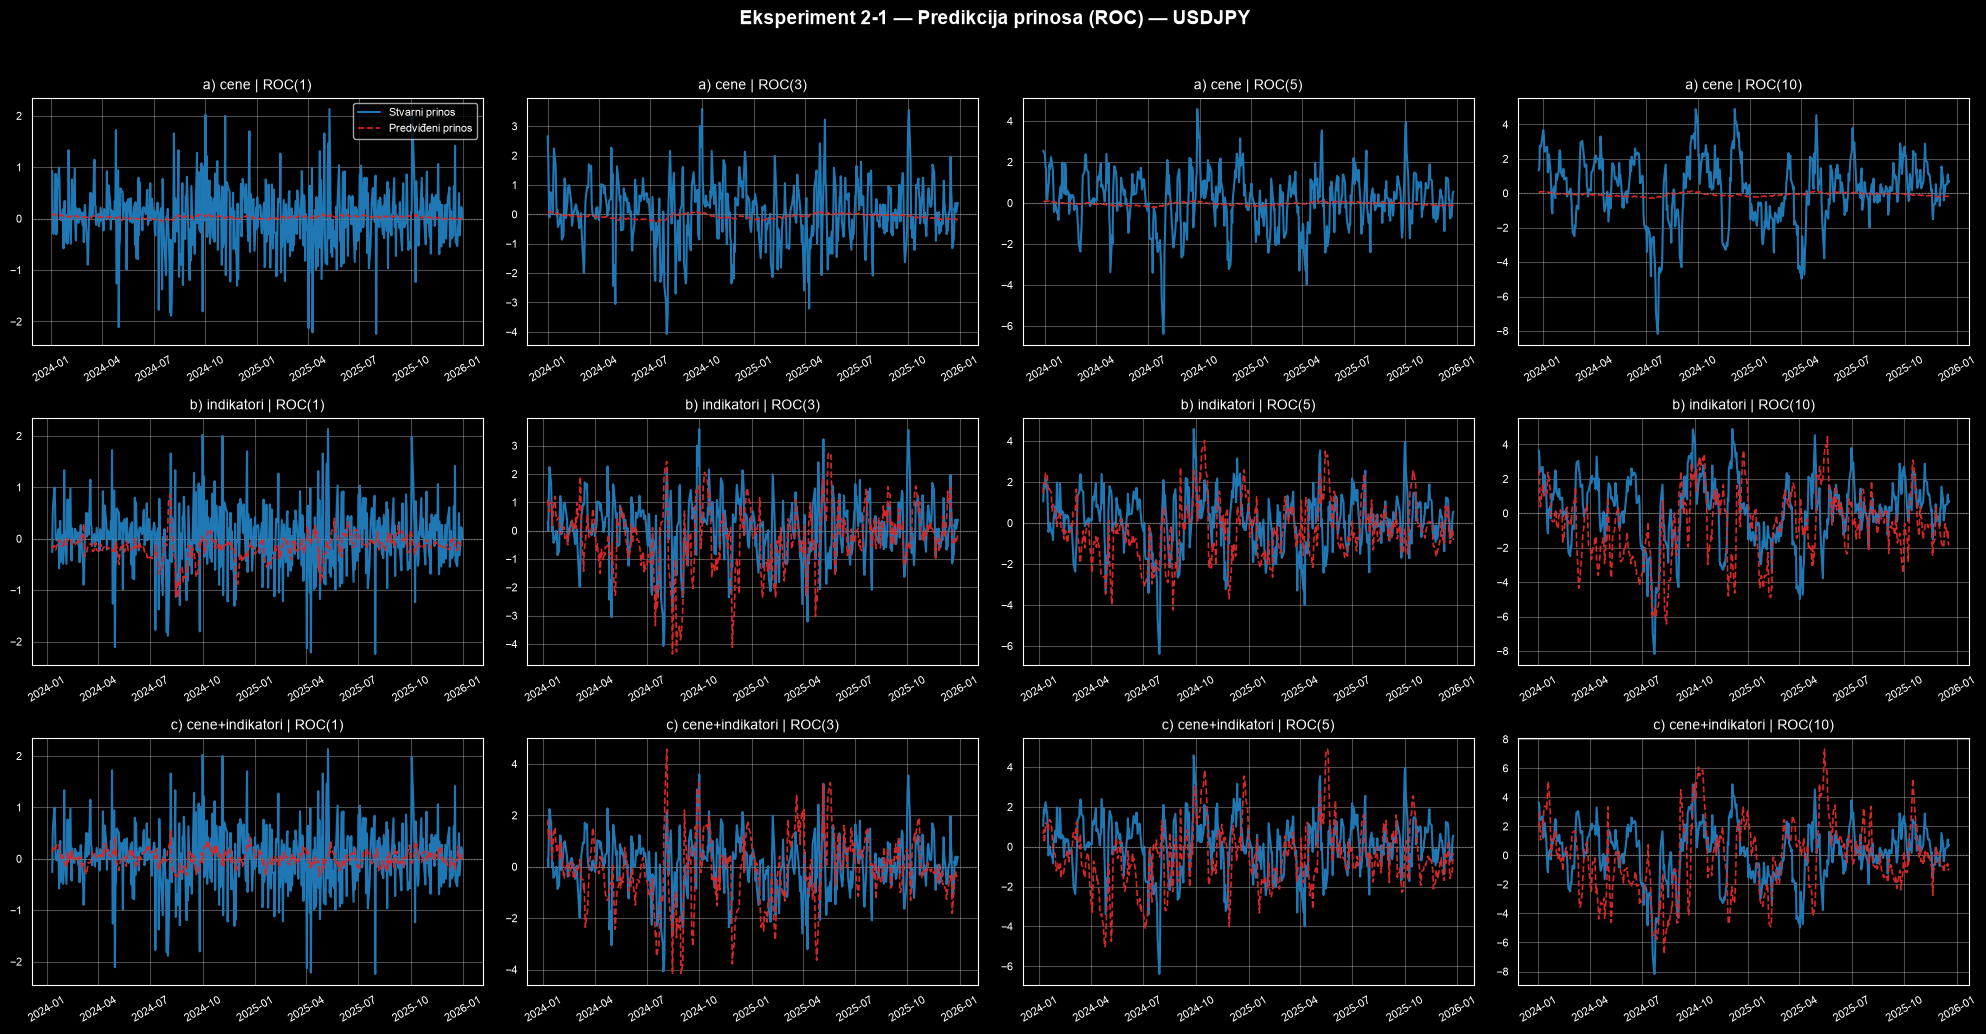

In [8]:
SUBCASES_2_1 = ['a) cene', 'b) indikatori', 'c) cene+indikatori']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_2_1), len(RETURN_HORIZONS),
                              figsize=(5 * len(RETURN_HORIZONS), 3.5 * len(SUBCASES_2_1)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 2-1 — Predikcija prinosa (ROC) — {pair_name}",
                 fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_2_1):
        for col, h in enumerate(RETURN_HORIZONS):
            ax  = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_2_1:
                ax.set_title(f"{subcase} | ROC({h}) (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_2_1[key]
            ax.plot(data['dates'], data['y_test'], label='Stvarni prinos', color='#1f77b4', linewidth=1.5)
            ax.plot(data['dates'], data['y_pred'], label='Predviđeni prinos', color='#d62728',
                    linewidth=1.2, linestyle='--')
            ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')

            ax.set_title(f"{subcase} | ROC({h})", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 📉 FAZA 4b: Learning curves (gubitak po iteracijama) — najbolja praksa iz literature

Kao u PyTorch i Keras/TDS tutorijalima za regresiju neuronskim mrežama, posle treniranja
proveravamo **krivu gubitka (loss curve)** kroz iteracije/epohe, ne samo finalne metrike:

- `loss_curve_` — train loss (MSE) po iteraciji (analogno `history` listi iz PyTorch tutoriala
  i `loss` iz Keras `model.fit()` izveštaja).
- `validation_scores_` — validacioni skor po iteraciji kada je `early_stopping=True`
  (analogno `val_loss` iz Keras tutoriala).

Ako kriva gubitka opada i stabilizuje se (ne raste ponovo), model je dobro konvergirao i
nije overfit-ovao trening skup. Prikazujemo reprezentativni podslučaj **c) cene+indikatori**
za Eksperiment 2-1, za sve parove i sve horizonte ROC-a.

In [9]:
REPR_SUBCASE_2_1 = 'c) cene+indikatori'

pairs_lc = list(features['Pair'].unique())

fig, axes = plt.subplots(len(pairs_lc), len(RETURN_HORIZONS),
                          figsize=(4.5 * len(RETURN_HORIZONS), 3 * len(pairs_lc)),
                          squeeze=False)
fig.suptitle(f"Learning curves (MLP loss po iteraciji) — Eksperiment 2-1 | {REPR_SUBCASE_2_1}",
             fontsize=14, fontweight='bold')

for ri, pair_name in enumerate(pairs_lc):
    for ci, h in enumerate(RETURN_HORIZONS):
        ax  = axes[ri][ci]
        key = (pair_name, REPR_SUBCASE_2_1, h)

        if key not in predictions_2_1 or not predictions_2_1[key].get('loss_curve'):
            ax.set_title(f"{pair_name} | ROC({h}) (nema podataka)", fontsize=9)
            ax.axis('off')
            continue

        data = predictions_2_1[key]
        loss_curve = data['loss_curve']
        val_scores = data.get('validation_scores', [])

        ax.plot(loss_curve, label='Train loss (MSE)', color='#1f77b4', linewidth=1.4)
        if val_scores:
            # validation_scores_ je R² po default-u u sklearn-u (veće=bolje),
            # pa ga prikazujemo na sekundarnoj y-osi radi jasnoće
            ax2 = ax.twinx()
            ax2.plot(val_scores, label='Validation R²', color='#2ca02c',
                     linewidth=1.2, linestyle='--')
            ax2.set_ylabel('Val R²', fontsize=7, color='#2ca02c')
            ax2.tick_params(axis='y', labelsize=7, labelcolor='#2ca02c')

        ax.set_title(f"{pair_name} | ROC({h})", fontsize=9)
        ax.set_xlabel('Iteracija', fontsize=7)
        ax.set_ylabel('Train loss', fontsize=7)
        ax.tick_params(labelsize=7)
        ax.grid(alpha=0.3)
        if ri == 0 and ci == 0:
            ax.legend(fontsize=7, loc='upper right')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


✓ Learning curves prikazane. Kriva koja se ravna pre max_iter ukazuje na rano zaustavljanje (early stopping).


## 🧪 EKSPERIMENT 2-2: Predikcija prinosa + ROC od ulaznih varijabli

### Feature seti:
- **a)** Lagovane CENE + ROC od CENA → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **b)** Lagovani INDIKATORI + ROC od INDIKATORA → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **c)** Sve gore + ROC od CENA i ROC od INDIKATORA → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)


In [10]:
predictions_2_2 = {}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # ── Feature blokovi ────────────────────────────────────────────────────
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)          # ROC od CENA

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14) # ROC od INDIKATORA

    # ── Targetni prinosi ───────────────────────────────────────────────────
    targets = add_return_targets(pdf, RETURN_HORIZONS)

    feature_sets = {
        'a) cene+ROC(cena)':    (pd.concat([price_lags, roc_price], axis=1),                          'standard'),
        'b) ind+ROC(ind)':      (pd.concat([indicator_lags, roc_indicators], axis=1),                  'robust'),
        'c) cene+ind+ROC(oba)': (pd.concat([price_lags, roc_price, indicator_lags, roc_indicators], axis=1), 'robust'),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in RETURN_HORIZONS:
            target_col = f'ROC_Target_{h}'
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X         = combo[X_df.columns].values
            y         = combo[target_col].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-2 {subcase} | {pair_name} | ROC({h})] "
                  f"MAE={metrics['MAE']:.4f} RMSE={metrics['RMSE']:.4f} "
                  f"R2={metrics['R2']:.4f} DirAcc={metrics['DirAcc']:.1f}% "
                  f"| feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '2-2', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'],   'MAPE': metrics['MAPE'], 'MedAE': metrics['MedAE'],
                'DirAcc': metrics['DirAcc'],
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_2_2[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
                'loss_curve': metrics['loss_curve'],
                'validation_scores': metrics['validation_scores'],
            }

print("\n✓ Eksperiment 2-2 završen.")

[2-2 c) cene+ind+ROC(oba) | USDJPY | ROC(10)] MAE=1.7951 RMSE=2.2454 R2=-0.4075 DirAcc=56.7% | feat=58 iter=95 ✓konv.

✓ Eksperiment 2-2 završen.


### 📈 Vizualizacija predikcija — Eksperiment 2-2

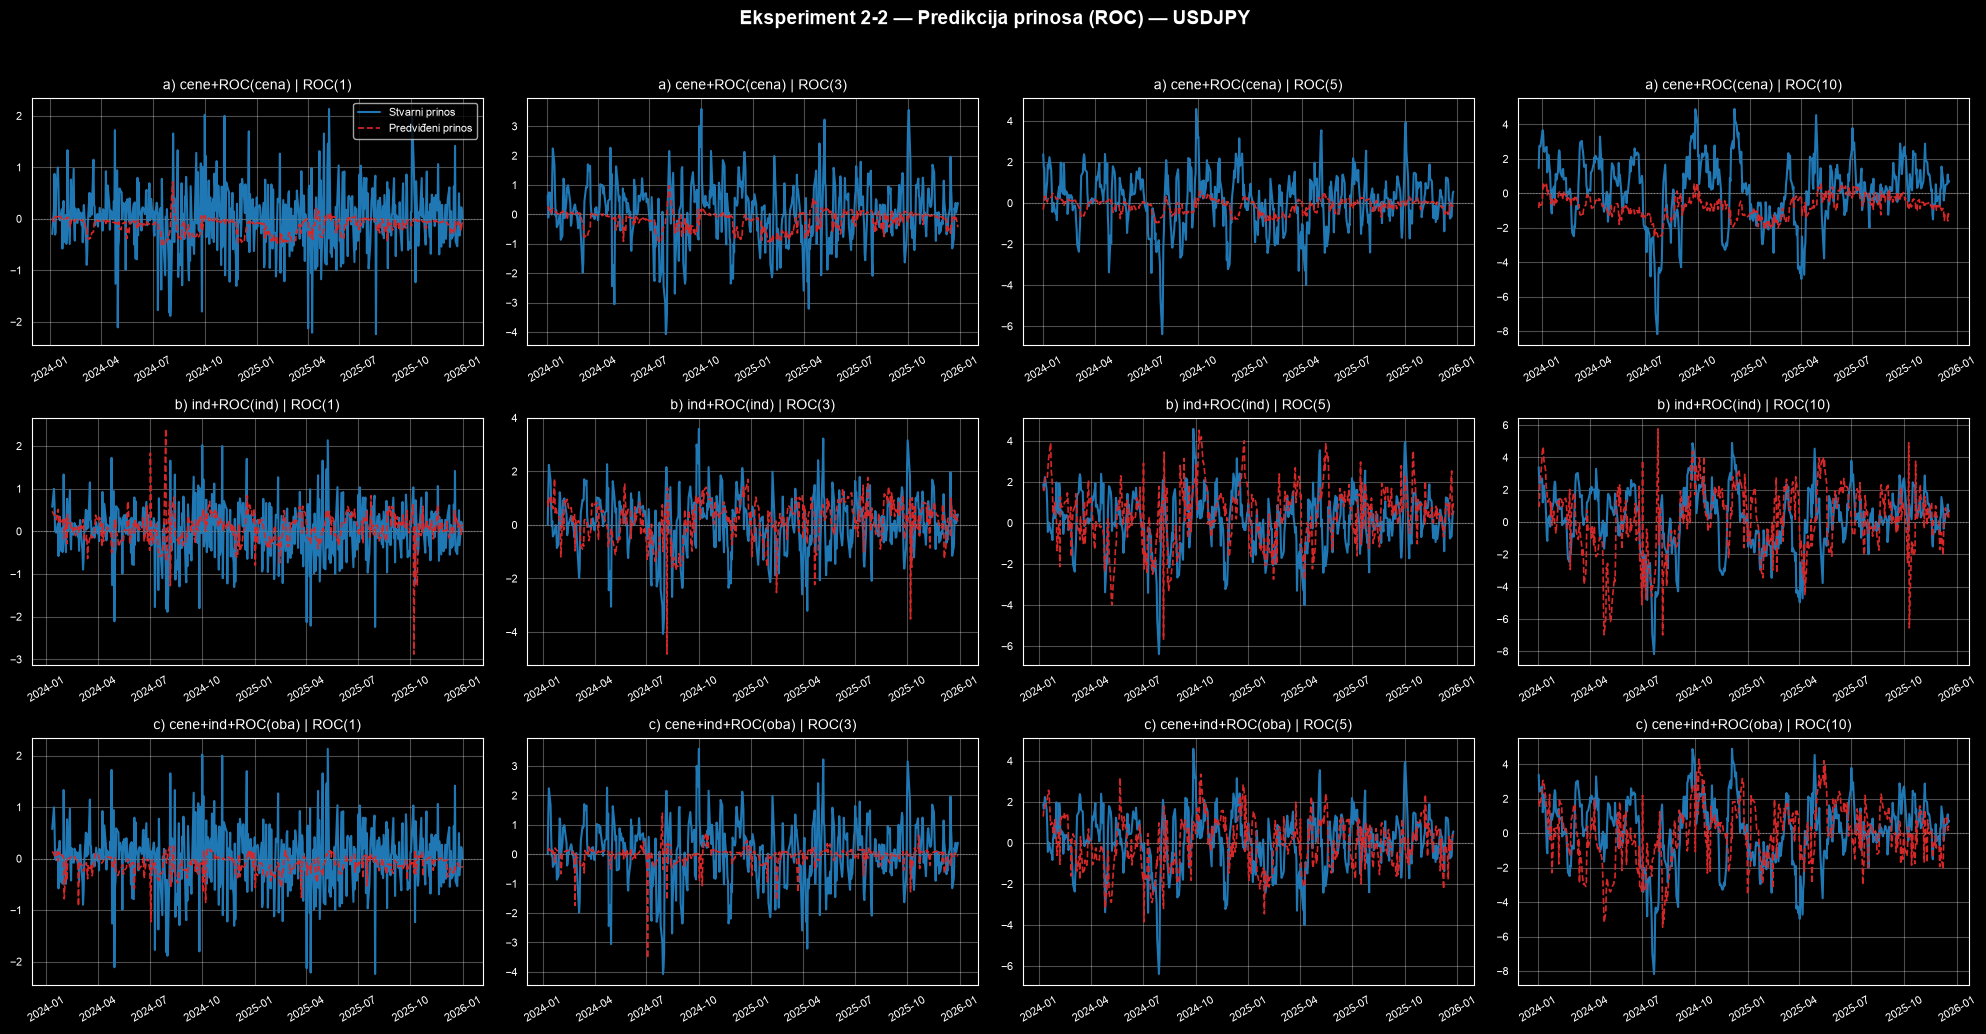

In [11]:
SUBCASES_2_2 = ['a) cene+ROC(cena)', 'b) ind+ROC(ind)', 'c) cene+ind+ROC(oba)']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_2_2), len(RETURN_HORIZONS),
                              figsize=(5 * len(RETURN_HORIZONS), 3.5 * len(SUBCASES_2_2)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 2-2 — Predikcija prinosa (ROC) — {pair_name}",
                 fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_2_2):
        for col, h in enumerate(RETURN_HORIZONS):
            ax  = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_2_2:
                ax.set_title(f"{subcase} | ROC({h}) (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_2_2[key]
            ax.plot(data['dates'], data['y_test'], label='Stvarni prinos', color='#1f77b4', linewidth=1.5)
            ax.plot(data['dates'], data['y_pred'], label='Predviđeni prinos', color='#d62728',
                    linewidth=1.2, linestyle='--')
            ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')

            ax.set_title(f"{subcase} | ROC({h})", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 🧪 EKSPERIMENT 2-3: Predikcija prinosa + ROC + SMA od ulaznih varijabli

### Feature seti:
- **a)** Lagovane CENE + ROC od CENA + SMA od CENA → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **b)** Lagovani INDIKATORI + ROC od INDIKATORA + SMA od INDIKATORA → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)
- **c)** Sve kombinovano → predviđamo ROC(1), ROC(3), ROC(5), ROC(10)


In [12]:
predictions_2_3 = {}

for pair_name in features['Pair'].unique():
    pdf = features[features['Pair'] == pair_name].sort_values('Date').reset_index(drop=True)

    # ── Feature blokovi ────────────────────────────────────────────────────
    price_lags = pd.DataFrame(index=pdf.index)
    for lag in range(1, N_LAGS + 1):
        price_lags[f'Price_lag{lag}'] = pdf['Price'].shift(lag)
    roc_price = add_roc(pdf, ['Price'], 14)
    sma_price = add_sma(pdf, ['Price'], 14)

    indicator_lags = pd.DataFrame(index=pdf.index)
    for col in INDICATOR_COLS:
        indicator_lags[col] = pdf[col]
        for lag in range(1, N_LAGS_INDICATORS + 1):
            indicator_lags[f'{col}_lag{lag}'] = pdf[col].shift(lag)
    roc_indicators = add_roc(pdf, INDICATOR_COLS, 14)
    sma_indicators = add_sma(pdf, INDICATOR_COLS, 14)

    # ── Targetni prinosi ───────────────────────────────────────────────────
    targets = add_return_targets(pdf, RETURN_HORIZONS)

    feature_sets = {
        'a) cene+ROC+SMA(cena)': (
            pd.concat([price_lags, roc_price, sma_price], axis=1),
            'standard'
        ),
        'b) ind+ROC+SMA(ind)': (
            pd.concat([indicator_lags, roc_indicators, sma_indicators], axis=1),
            'robust'
        ),
        'c) sve kombinovano': (
            pd.concat([price_lags, roc_price, sma_price,
                       indicator_lags, roc_indicators, sma_indicators], axis=1),
            'robust'
        ),
    }

    for subcase, (X_df, scaler_type) in feature_sets.items():
        for h in RETURN_HORIZONS:
            target_col = f'ROC_Target_{h}'
            combo = pd.concat([X_df, targets[[target_col]], pdf[['Date']]], axis=1).dropna()
            if len(combo) < 50:
                continue

            X         = combo[X_df.columns].values
            y         = combo[target_col].values
            dates_arr = combo['Date'].values

            metrics = run_regression(X, y, dates=dates_arr, scaler_type=scaler_type)
            if metrics is None:
                continue

            conv_flag = "✓konv." if metrics['converged'] else "⚠NIJE konvergirao"
            print(f"[2-3 {subcase} | {pair_name} | ROC({h})] "
                  f"MAE={metrics['MAE']:.4f} RMSE={metrics['RMSE']:.4f} "
                  f"R2={metrics['R2']:.4f} DirAcc={metrics['DirAcc']:.1f}% "
                  f"| feat={metrics['n_features']} iter={metrics['n_iter']} {conv_flag}")

            results_all.append({
                'Experiment': '2-3', 'Subcase': subcase, 'Pair': pair_name,
                'Horizon': f'ROC({h})',
                'MAE': metrics['MAE'], 'RMSE': metrics['RMSE'],
                'R2': metrics['R2'],   'MAPE': metrics['MAPE'], 'MedAE': metrics['MedAE'],
                'DirAcc': metrics['DirAcc'],
                'Train_Size': metrics['Train_Size'], 'Test_Size': metrics['Test_Size'],
                'N_Features': metrics['n_features'], 'N_Iter': metrics['n_iter'],
                'Converged': metrics['converged'],
            })

            predictions_2_3[(pair_name, subcase, h)] = {
                'dates': metrics['test_dates'],
                'y_test': metrics['y_test'],
                'y_pred': metrics['y_pred'],
                'loss_curve': metrics['loss_curve'],
                'validation_scores': metrics['validation_scores'],
            }

print("\n✓ Eksperiment 2-3 završen.")

[2-3 c) sve kombinovano | USDJPY | ROC(10)] MAE=1.7646 RMSE=2.3080 R2=-0.4870 DirAcc=58.0% | feat=72 iter=127 ✓konv.

✓ Eksperiment 2-3 završen.


### 📈 Vizualizacija predikcija — Eksperiment 2-3

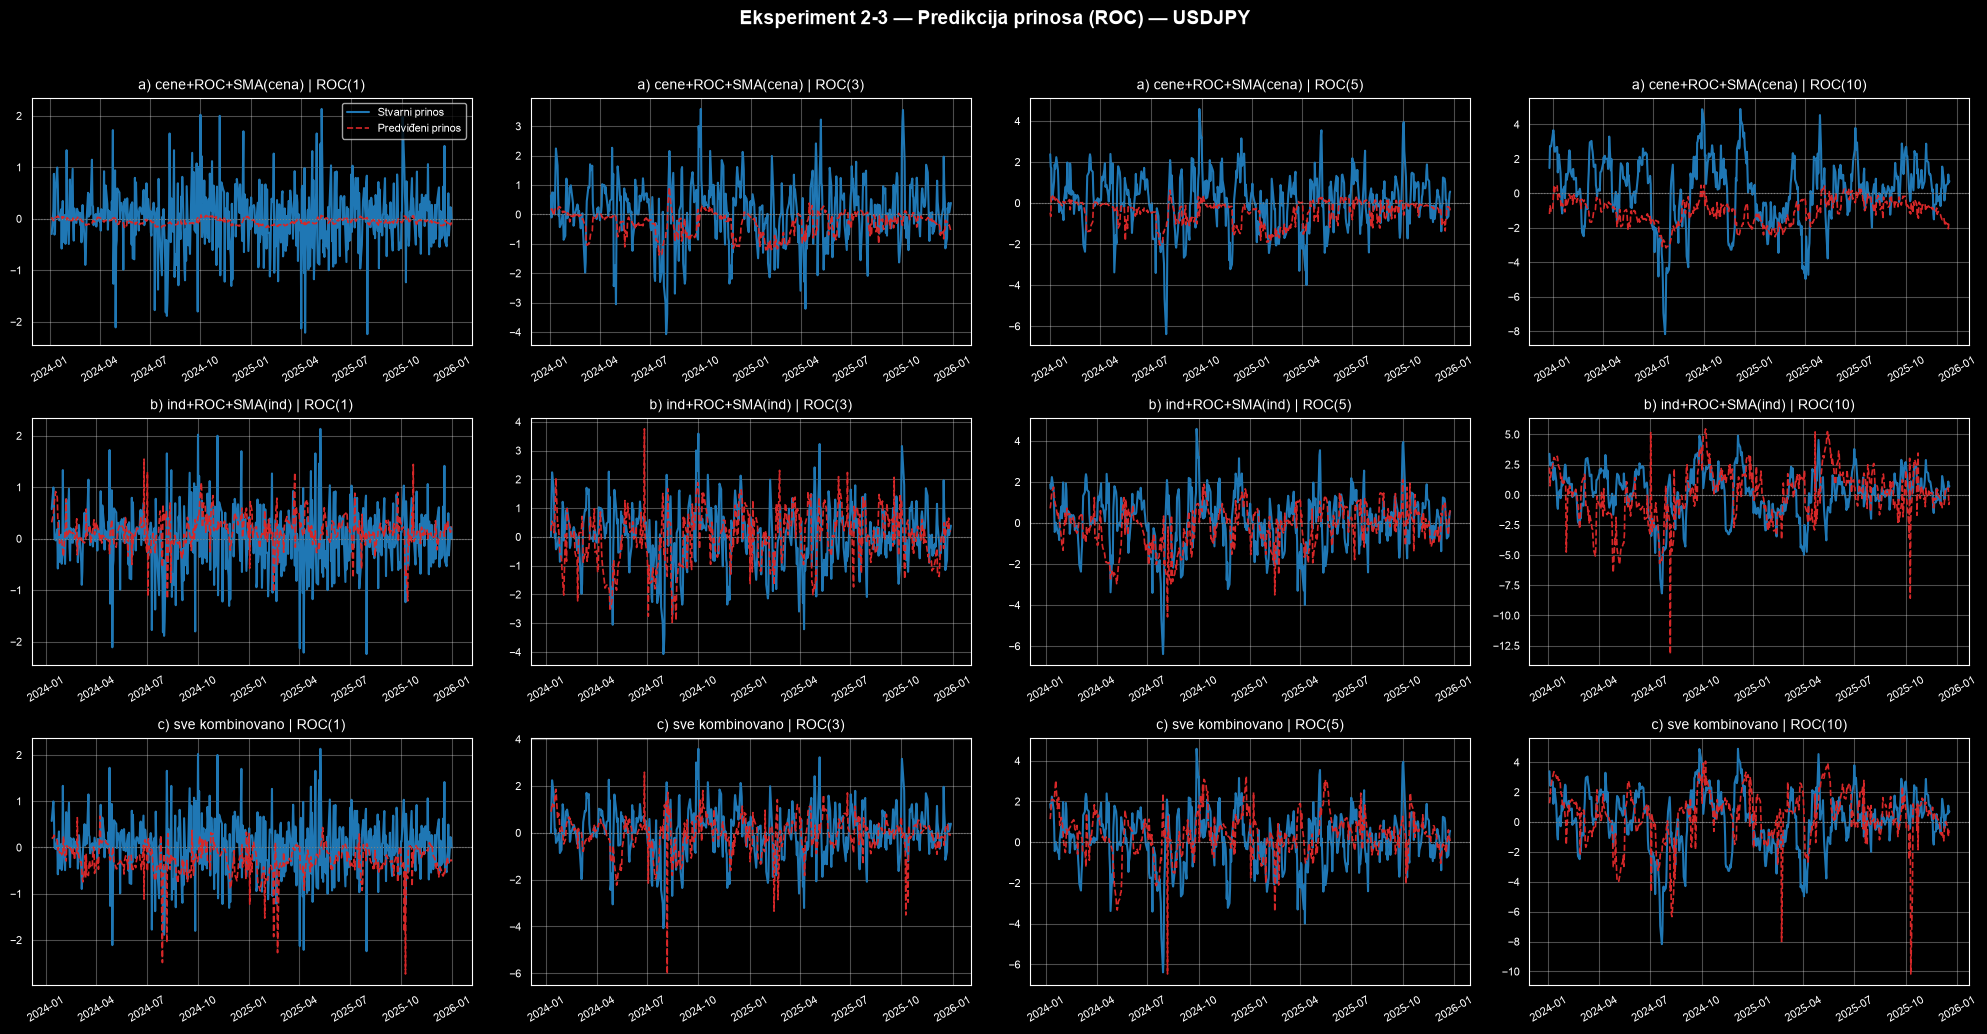

In [13]:
SUBCASES_2_3 = ['a) cene+ROC+SMA(cena)', 'b) ind+ROC+SMA(ind)', 'c) sve kombinovano']

for pair_name in features['Pair'].unique():
    fig, axes = plt.subplots(len(SUBCASES_2_3), len(RETURN_HORIZONS),
                              figsize=(5 * len(RETURN_HORIZONS), 3.5 * len(SUBCASES_2_3)),
                              squeeze=False)
    fig.suptitle(f"Eksperiment 2-3 — Predikcija prinosa (ROC) — {pair_name}",
                 fontsize=14, fontweight='bold')

    for row, subcase in enumerate(SUBCASES_2_3):
        for col, h in enumerate(RETURN_HORIZONS):
            ax  = axes[row][col]
            key = (pair_name, subcase, h)

            if key not in predictions_2_3:
                ax.set_title(f"{subcase} | ROC({h}) (nema podataka)")
                ax.axis('off')
                continue

            data = predictions_2_3[key]
            ax.plot(data['dates'], data['y_test'], label='Stvarni prinos', color='#1f77b4', linewidth=1.5)
            ax.plot(data['dates'], data['y_pred'], label='Predviđeni prinos', color='#d62728',
                    linewidth=1.2, linestyle='--')
            ax.axhline(0, color='gray', linewidth=0.8, linestyle=':')

            ax.set_title(f"{subcase} | ROC({h})", fontsize=10)
            ax.xaxis.set_major_locator(mdates.AutoDateLocator())
            ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
            ax.tick_params(axis='x', rotation=30, labelsize=8)
            ax.tick_params(axis='y', labelsize=8)
            ax.grid(alpha=0.3)
            if row == 0 and col == 0:
                ax.legend(fontsize=8, loc='best')

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()


## 📊 FAZA 5: Zbirni rezultati svih eksperimenata

In [14]:
results_df = pd.DataFrame(results_all)
results_df = results_df[['Experiment', 'Subcase', 'Pair', 'Horizon',
                          'MAE', 'RMSE', 'R2', 'MAPE', 'MedAE', 'DirAcc',
                          'Train_Size', 'Test_Size', 'N_Features', 'N_Iter', 'Converged']]

print("="*110)
print(f"SVI REZULTATI — {len(results_df)} kombinacija (eksperiment × podslučaj × par × horizont)")
print("="*110 + "\n")
print(results_df.to_string(index=False))

n_not_converged = (~results_df['Converged']).sum()
if n_not_converged > 0:
    print(f"\n⚠ Upozorenje: {n_not_converged} model(a) NIJE konvergiralo (zaglavilo na max_iter={MLP_PARAMS['max_iter']}).")
    print("   Razmotri dalje povećanje max_iter za te kombinacije.")

results_df.to_excel('Experiment2_Results.xlsx', index=False)

SVI REZULTATI — 216 kombinacija (eksperiment × podslučaj × par × horizont)

Experiment               Subcase   Pair Horizon      MAE     RMSE         R2        MAPE    MedAE    DirAcc  Train_Size  Test_Size  N_Features  N_Iter  Converged
       2-1               a) cene EURUSD  ROC(1) 0.319514 0.435283  -0.004408  102.577457 0.244376 46.641075        2083        521           5      39       True
       2-1               a) cene EURUSD  ROC(3) 0.552692 0.745838  -0.008109  114.347526 0.432956 55.854127        2081        521           5      87       True
       2-1               a) cene EURUSD  ROC(5) 0.708271 0.944131  -0.020035  158.903516 0.579835 53.653846        2080        520           5     105       True
       2-1               a) cene EURUSD ROC(10) 1.013548 1.320450   0.004865  132.415054 0.864404 51.445087        2076        519           5      62       True
       2-1         b) indikatori EURUSD  ROC(1) 0.352516 0.472455  -0.171981  177.900470 0.283621 50.097087       

## 🔀 FAZA 6: Confusion Matrix smera prinosa (UP/DOWN)

### Napomena:
U Eksperimentu 2 binarizujemo **sam prinos** (ne promenu cene):
- **UP (1)** = predviđeni/stvarni prinos > 0 (zarada)
- **DOWN (0)** = predviđeni/stvarni prinos ≤ 0 (gubitak)

Ovo je direktno merilo korisnosti modela za trading odluke.


In [15]:
from sklearn.metrics import confusion_matrix

def return_direction_labels(y_arr):
    """Binarna klasifikacija prinosa: 1=pozitivan prinos, 0=negativan/nula.
    Razlika od Eksperimenta 1: tamo smo uzimali diff(y) da dobijemo smer promene,
    ovde je y već prinos pa direktno gledamo znak.
    """
    return (np.array(y_arr) > 0).astype(int)

def plot_confusion_matrix(cm, ax, title, classes=["DOWN", "UP"]):
    """Prikaži normalizovanu confusion matrix."""
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
    ax.set_title(title, fontsize=8, pad=4)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(classes, fontsize=8)
    ax.set_yticklabels(classes, fontsize=8)
    ax.set_ylabel('Stvarno', fontsize=7)
    ax.set_xlabel('Predviđeno', fontsize=7)
    for i, j in itertools.product(range(2), range(2)):
        ax.text(j, i, f"{cm[i,j]}\n({cm_norm[i,j]:.0%})",
                ha='center', va='center', fontsize=8,
                color='white' if cm_norm[i, j] > 0.5 else 'black')

# Skupi predikcije iz sva 3 eksperimenta
all_predictions = {}
for key, val in predictions_2_1.items():
    pair, sub, h = key
    all_predictions[('2-1', pair, sub, h)] = val
for key, val in predictions_2_2.items():
    pair, sub, h = key
    all_predictions[('2-2', pair, sub, h)] = val
for key, val in predictions_2_3.items():
    pair, sub, h = key
    all_predictions[('2-3', pair, sub, h)] = val

# Tabelarni prikaz confusion matrix metrika
cm_records = []
for (exp, pair, sub, h), data in all_predictions.items():
    yt = data['y_test']
    yp = data['y_pred']
    if len(yt) < 5:
        continue

    true_dir = return_direction_labels(yt)
    pred_dir = return_direction_labels(yp)
    n = min(len(true_dir), len(pred_dir))
    true_dir, pred_dir = true_dir[:n], pred_dir[:n]

    cm = confusion_matrix(true_dir, pred_dir, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    acc  = (tp + tn) / (tp + tn + fp + fn + 1e-9) * 100
    prec = tp / (tp + fp + 1e-9) * 100
    rec  = tp / (tp + fn + 1e-9) * 100
    f1   = 2 * prec * rec / (prec + rec + 1e-9)

    cm_records.append({
        'Experiment': exp, 'Subcase': sub, 'Pair': pair, 'Horizon': h,
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
        'Accuracy_%':  round(acc,  1),
        'Precision_%': round(prec, 1),
        'Recall_%':    round(rec,  1),
        'F1_%':        round(f1,   1),
    })

cm_df = pd.DataFrame(cm_records)
print("="*110)
print(f"CONFUSION MATRIX METRIKE (smer prinosa UP/DOWN) — {len(cm_df)} kombinacija")
print("="*110)
print(cm_df.to_string(index=False))

cm_df.to_excel('Experiment2_ConfusionMatrix.xlsx', index=False)


✓ Sačuvano: Experiment2_ConfusionMatrix.xlsx


### 📊 Vizuelni grid Confusion Matrica — Eksperiment 2-1, podslučaj c) (reprezentativan prikaz)

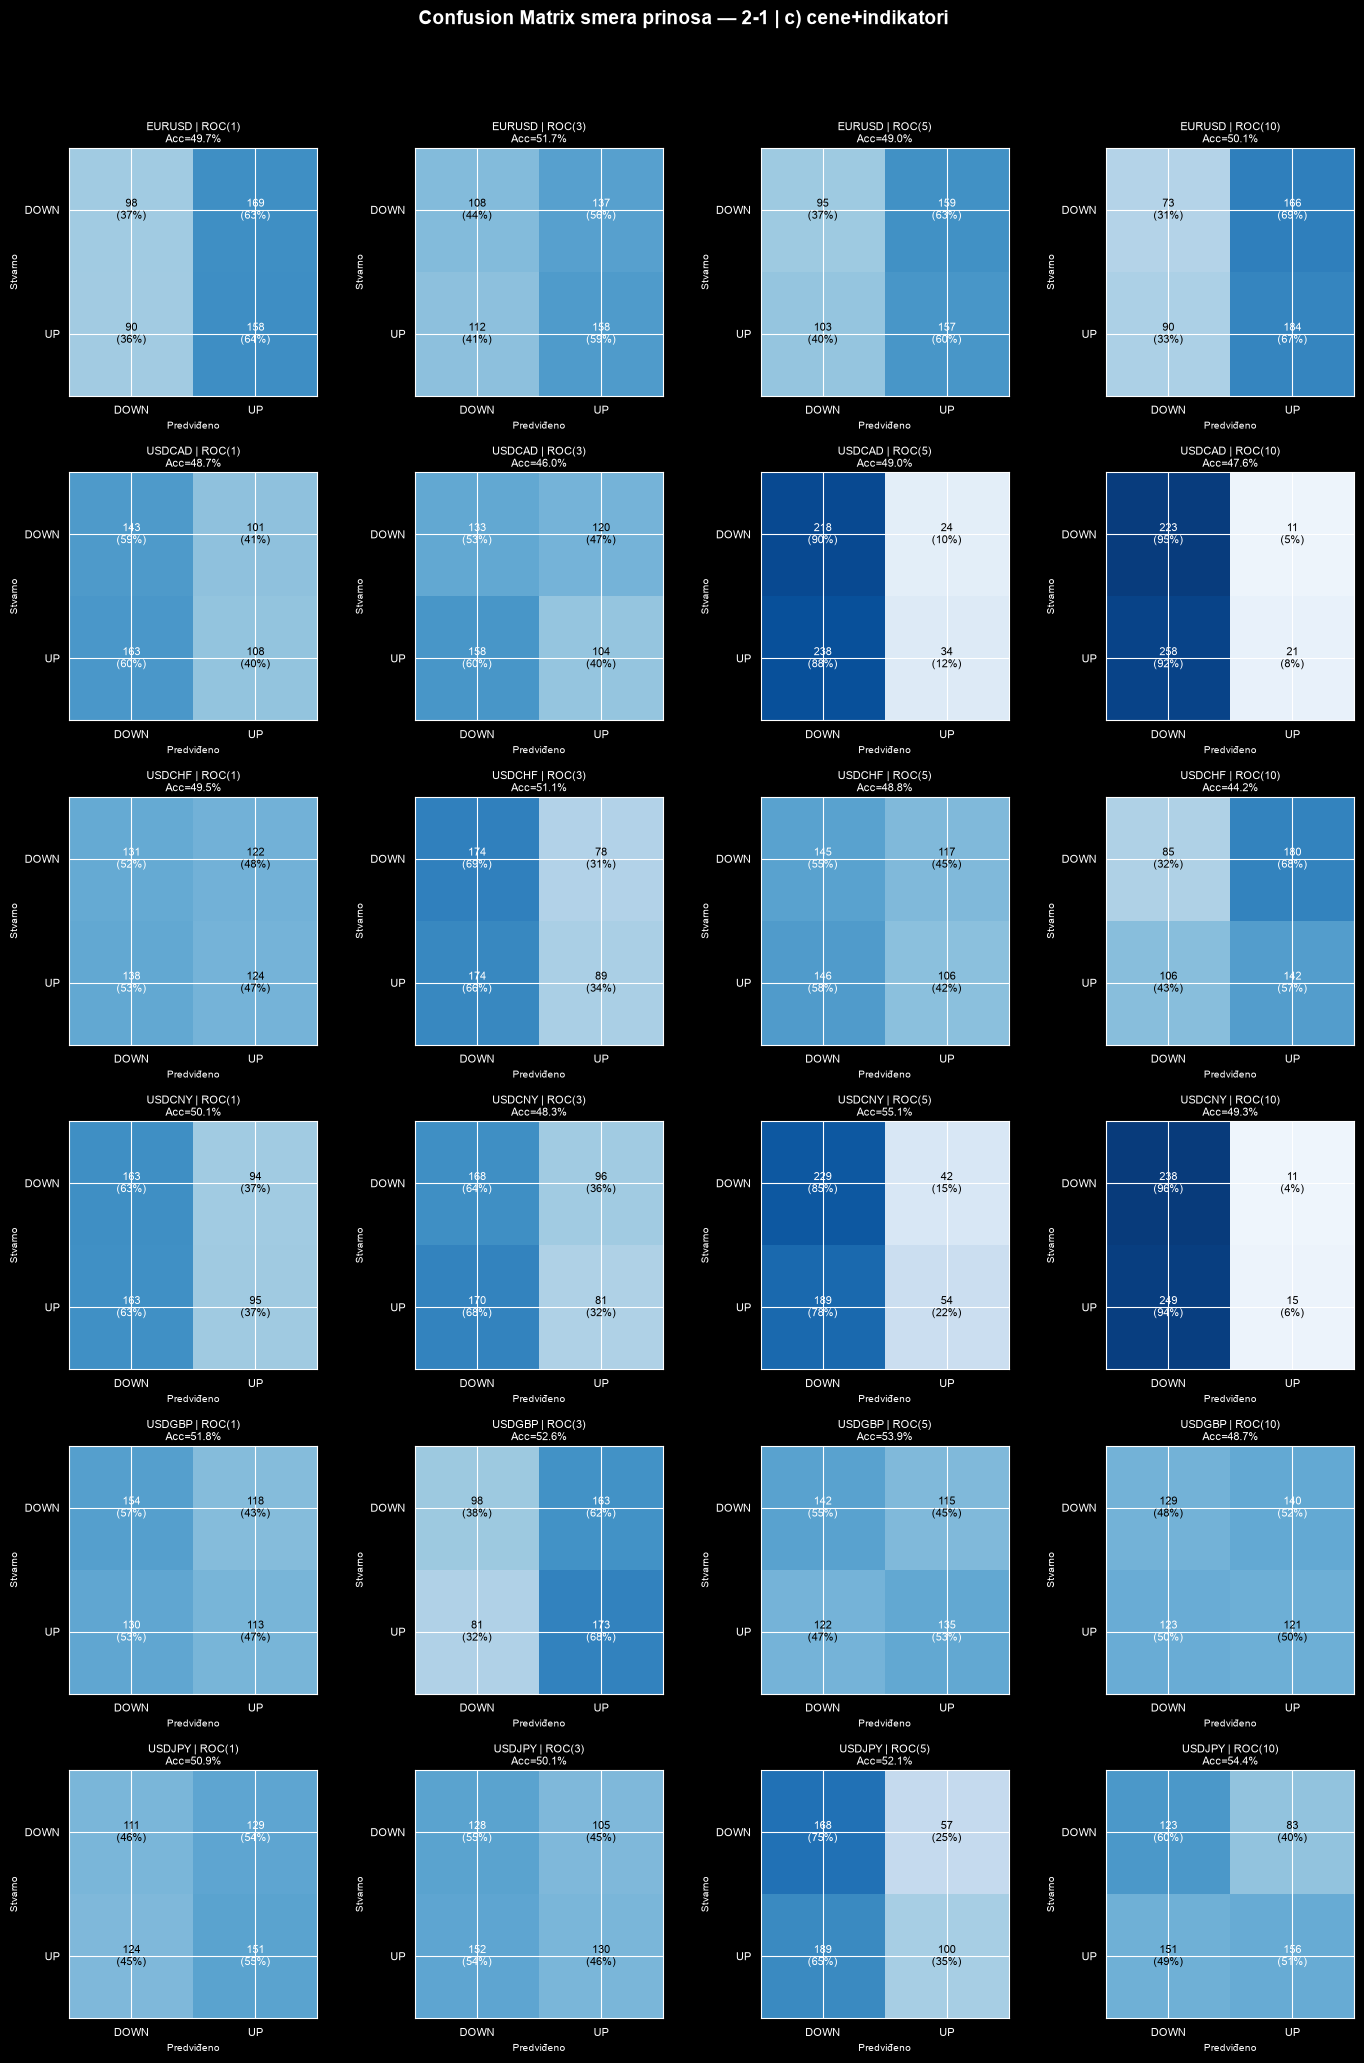

In [16]:
TARGET_EXP = '2-1'
TARGET_SUB = 'c) cene+indikatori'

pairs    = sorted(set(k[1] for k in all_predictions if k[0] == TARGET_EXP and k[2] == TARGET_SUB))
horizons = sorted(set(k[3] for k in all_predictions if k[0] == TARGET_EXP and k[2] == TARGET_SUB))

if not pairs or not horizons:
    print("Nema podataka za prikaz.")
else:
    fig, axes = plt.subplots(len(pairs), len(horizons),
                              figsize=(3.5 * len(horizons), 3.5 * len(pairs)),
                              squeeze=False)
    fig.suptitle(f"Confusion Matrix smera prinosa — {TARGET_EXP} | {TARGET_SUB}",
                 fontsize=14, fontweight='bold')

    for ri, pair in enumerate(pairs):
        for ci, h in enumerate(horizons):
            ax  = axes[ri][ci]
            key = (TARGET_EXP, pair, TARGET_SUB, h)

            if key not in all_predictions:
                ax.set_visible(False)
                continue

            data = all_predictions[key]
            true_dir = return_direction_labels(data['y_test'])
            pred_dir = return_direction_labels(data['y_pred'])
            n = min(len(true_dir), len(pred_dir))
            true_dir, pred_dir = true_dir[:n], pred_dir[:n]

            cm   = confusion_matrix(true_dir, pred_dir, labels=[0, 1])
            acc  = (cm[0, 0] + cm[1, 1]) / cm.sum() * 100
            plot_confusion_matrix(cm, ax, f"{pair} | ROC({h})\nAcc={acc:.1f}%")

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


## 💾 FAZA 7: Export svih fajlova

In [17]:
missing_df.to_excel('00_Missing_Values_Report.xlsx', index=False)
currency_all.to_csv('01_Currency_Data_ALL.csv', index=False)
features.to_csv('02_Features_With_Indicators.csv', index=False)

print("✓ Sačuvani fajlovi:")
print("  - 00_Missing_Values_Report.xlsx")
print("  - 01_Currency_Data_ALL.csv")
print("  - 02_Features_With_Indicators.csv")
print("  - Experiment2_Results.xlsx         (svi rezultati 2-1, 2-2, 2-3)")
print("  - Experiment2_ConfusionMatrix.xlsx (CM metrike po smeru prinosa)")
print()
print("="*60)
print(f"Ukupno istreniranih modela: {len(results_df)}")
print(f"  Eksperiment 2-1: {len(results_df[results_df.Experiment=='2-1'])} modela")
print(f"  Eksperiment 2-2: {len(results_df[results_df.Experiment=='2-2'])} modela")
print(f"  Eksperiment 2-3: {len(results_df[results_df.Experiment=='2-3'])} modela")
print("="*60)

✓ Sačuvani fajlovi:
  - 00_Missing_Values_Report.xlsx
  - 01_Currency_Data_ALL.csv
  - 02_Features_With_Indicators.csv
  - Experiment2_Results.xlsx         (svi rezultati 2-1, 2-2, 2-3)
  - Experiment2_ConfusionMatrix.xlsx (CM metrike po smeru prinosa)

Ukupno istreniranih modela: 216
  Eksperiment 2-1: 72 modela
  Eksperiment 2-2: 72 modela
  Eksperiment 2-3: 72 modela
